![Universidad Iberoamericana del Ecuador](https://raw.githubusercontent.com/andresrubiop/ml-unibe-estudiantes/main/utils/logo-unibe-color.png)

<div style="background:#004890;color:#FFFFFF;padding:14px 18px;border-radius:10px;margin:6px 0 12px 0;border-bottom:4px solid #FCC000"><div style="font-size:12px;letter-spacing:.08em;text-transform:uppercase;opacity:.9">Machine Learning · Tutoría asíncrona · deep learning · Versión resuelta · referencia</div><div style="font-size:22px;font-weight:700;margin-top:4px">LT.1 · Del perceptrón a la red convolucional con PyTorch</div><div style="font-size:12px;opacity:.9;margin-top:4px">Posgrado · Maestría en Big Data y Ciencia de Datos · UNIB.E</div></div>

| | |
|---|---|
| **Objetivo** | Construir y entrenar redes neuronales con PyTorch, desde una sola capa (que es la regresión softmax de la sesión 1) hasta una red convolucional, y comparar con los modelos clásicos. |
| **Duración** | ≈ 45 min (parte de la tutoría asíncrona de 1,5 h) |
| **Teoría** | Manual MT1 · Animación AT.1 · Presentación PT1 |
| **Datos icónicos** | **MNIST** completo (60 000 + 10 000 imágenes de 28 × 28) |
| **Escala realista** | **Fashion-MNIST** con la misma red convolucional |

**Partes:** 0 · el bucle de entrenamiento → 1 · una capa lineal = regresión softmax → 2 · red con una capa oculta → 3 · red profunda con *dropout* y parada temprana → 4 · red convolucional → 5 · Fashion-MNIST.

Necesitas PyTorch (en Colab ya viene instalado). En tu equipo: `uv sync --extra dl` en el proyecto, o `pip install torch`. Todo corre en CPU en pocos minutos.

## 0 · Configuración y el bucle de entrenamiento

In [1]:
import os
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from cycler import cycler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split

warnings.filterwarnings("ignore")
SEED = 2026
torch.manual_seed(SEED)
UNIBE = {"azul": "#004890", "naranja": "#C2410C", "dorado": "#A87900", "verde": "#3A7D44", "gris": "#77787B"}
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=list(UNIBE.values())), "axes.titlecolor": UNIBE["azul"],
    "axes.titleweight": "bold", "axes.edgecolor": UNIBE["gris"], "axes.grid": True, "grid.color": "#E8EDF2",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "· dispositivo:", dispositivo)
CACHE = os.path.expanduser("~/.cache/ml-unibe")
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"   # copia pública de MNIST y Fashion-MNIST


def descargar(nombre):
    """Descarga un archivo de datos una sola vez y devuelve su ruta local."""
    os.makedirs(CACHE, exist_ok=True)
    ruta = os.path.join(CACHE, nombre)
    if not os.path.exists(ruta):
        urllib.request.urlretrieve(URL + nombre, ruta)
    return ruta


d = np.load(descargar("mnist.npz"))   # 11 MB la primera vez
x_tr = torch.tensor(d["x_train"], dtype=torch.float32).unsqueeze(1) / 255.0    # (60000, 1, 28, 28)
x_te = torch.tensor(d["x_test"], dtype=torch.float32).unsqueeze(1) / 255.0
y_tr, y_te = torch.tensor(d["y_train"], dtype=torch.long), torch.tensor(d["y_test"], dtype=torch.long)
print("Entrenamiento:", tuple(x_tr.shape), "· prueba:", tuple(x_te.shape))
resultados = {}

PyTorch 2.15.0+cu132 · dispositivo: cpu


Entrenamiento: (60000, 1, 28, 28) · prueba: (10000, 1, 28, 28)


En PyTorch el entrenamiento se escribe a mano, y eso es una ventaja para aprender: cada mini-lote recorre los mismos cuatro pasos del descenso de gradiente de la sesión 1.

1. **Hacia adelante:** el modelo calcula los puntajes (*logits*) del lote.
2. **Pérdida:** `nn.CrossEntropyLoss` aplica softmax a los puntajes y calcula la log-loss.
3. **Hacia atrás:** `perdida.backward()` calcula todos los gradientes con retropropagación.
4. **Paso:** el optimizador (Adam) mueve cada peso cuesta abajo.

Separamos un 10 % del entrenamiento para validar en cada época.

In [2]:
validacion = int(0.1 * len(x_tr))
ds_tr, ds_val = random_split(TensorDataset(x_tr, y_tr), [len(x_tr) - validacion, validacion],
                             generator=torch.Generator().manual_seed(SEED))


def exactitud_y_perdida(modelo, X, y, lote=2048):
    """Exactitud y pérdida promedio, sin calcular gradientes."""
    modelo.eval()
    perdida, aciertos = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(X), lote):
            z = modelo(X[i:i + lote].to(dispositivo))
            t = y[i:i + lote].to(dispositivo)
            perdida += nn.functional.cross_entropy(z, t, reduction="sum").item()
            aciertos += (z.argmax(1) == t).sum().item()
    return aciertos / len(X), perdida / len(X)


def entrenar(modelo, epocas=5, lote=128, paciencia=None, datos=None):
    """Entrena con Adam y mini-lotes; si hay paciencia, aplica parada temprana y recupera los mejores pesos."""
    datos = datos or (ds_tr, ds_val)
    modelo.to(dispositivo)
    opt = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    cargador = DataLoader(datos[0], batch_size=lote, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    Xv, yv = datos[1][:]
    hist = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    mejor, mejores_pesos, sin_mejora = float("inf"), None, 0
    for epoca in range(epocas):
        modelo.train()                                   # activa el dropout
        suma, aciertos, n = 0.0, 0, 0
        for xb, yb in cargador:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            z = modelo(xb)                               # 1 · hacia adelante
            perdida = nn.functional.cross_entropy(z, yb)  # 2 · pérdida (softmax + log-loss)
            opt.zero_grad()
            perdida.backward()                           # 3 · retropropagación
            opt.step()                                   # 4 · paso del optimizador
            suma += perdida.item() * len(yb); aciertos += (z.argmax(1) == yb).sum().item(); n += len(yb)
        acc_v, loss_v = exactitud_y_perdida(modelo, Xv, yv)
        for k, v in zip(hist, [suma / n, loss_v, aciertos / n, acc_v]):
            hist[k].append(v)
        if paciencia is not None:
            if loss_v < mejor - 1e-4:
                mejor, sin_mejora = loss_v, 0
                mejores_pesos = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
            else:
                sin_mejora += 1
                if sin_mejora >= paciencia:
                    break
    if mejores_pesos is not None:
        modelo.load_state_dict(mejores_pesos)
    return hist


def n_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())


def curvas(h, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(h["loss"], "o-", label="entrenamiento"); ax[0].plot(h["val_loss"], "s-", label="validación"); ax[0].set(title="pérdida", xlabel="época")
    ax[1].plot(h["accuracy"], "o-", label="entrenamiento"); ax[1].plot(h["val_accuracy"], "s-", label="validación"); ax[1].set(title="exactitud", xlabel="época")
    ax[1].legend(); fig.suptitle(titulo, color=UNIBE["azul"], fontweight="bold"); plt.tight_layout(); plt.show()

## Parte 1 · Una sola capa lineal: la regresión softmax de la sesión 1

`nn.Flatten` convierte cada imagen en un vector de 784 píxeles; `nn.Linear(784, 10)` calcula 10 puntajes $z_k = w_k^\top x + b_k$. La pérdida les aplica softmax. Es **exactamente** la regresión logística multinomial de L1.2, entrenada ahora con descenso de gradiente por mini-lotes.

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=10, bias=True)
)


Exactitud en la prueba: 0.9213 · parámetros: 7850


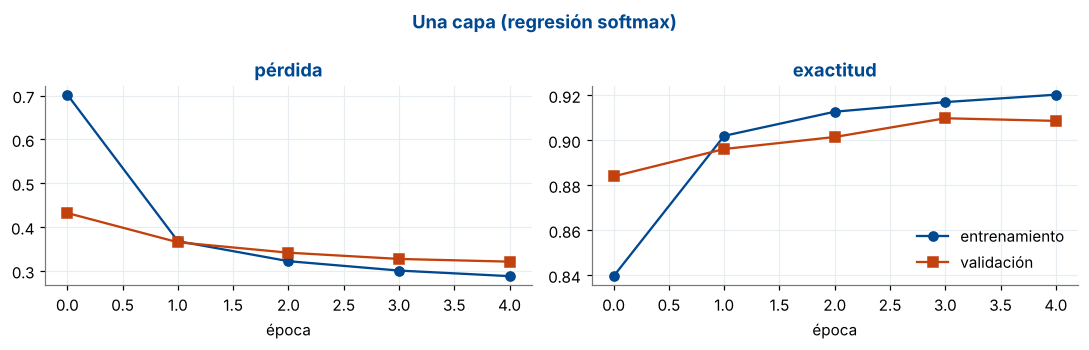

In [3]:
torch.manual_seed(SEED)
perceptron = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
print(perceptron)
t0 = time.perf_counter()
h1 = entrenar(perceptron, epocas=5)
resultados["1 capa (softmax)"] = (exactitud_y_perdida(perceptron, x_te, y_te)[0], n_parametros(perceptron), time.perf_counter() - t0)
print(f"Exactitud en la prueba: {resultados['1 capa (softmax)'][0]:.4f} · parámetros: {n_parametros(perceptron)}")
curvas(h1, "Una capa (regresión softmax)")

**Tu turno.** ¿Cuántos parámetros tiene esta red? Calcúlalo a mano: 784 pesos por cada una de las 10 clases, más 10 interceptos.

In [4]:
# TODO: escribe la cuenta de parámetros.
n_param = 784 * 10 + 10
assert n_param == n_parametros(perceptron)
print("✓", n_param, "parámetros: los mismos que la regresión softmax de scikit-learn")

✓ 7850 parámetros: los mismos que la regresión softmax de scikit-learn


## Parte 2 · Una capa oculta

Entre la entrada y la salida agregamos 128 neuronas con activación **ReLU**, $\max(0, z)$. Cada una aprende un detector de rasgos; la capa de salida combina esos rasgos.

Exactitud en la prueba: 0.9683 · parámetros: 101770


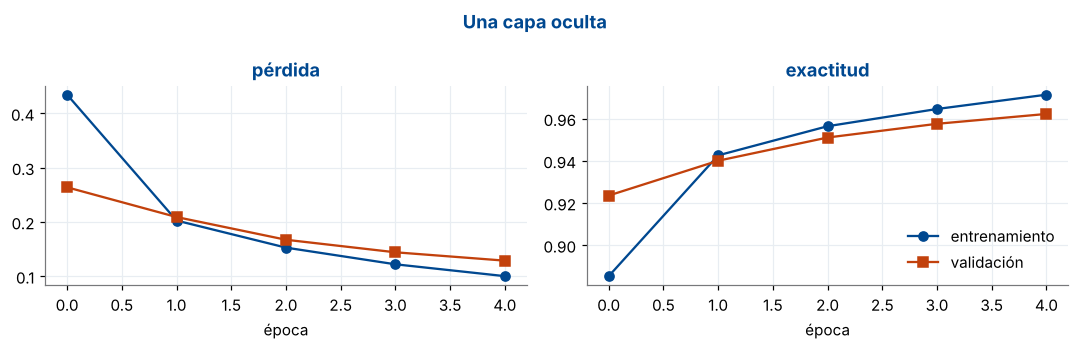

In [5]:
torch.manual_seed(SEED)
# TODO: arma la red Flatten → Linear(784, 128) → ReLU → Linear(128, 10) con nn.Sequential y entrénala 5 épocas.
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128), nn.ReLU(),
    nn.Linear(128, 10),
)
t0 = time.perf_counter()
h2 = entrenar(mlp, epocas=5)
resultados["1 capa oculta (128)"] = (exactitud_y_perdida(mlp, x_te, y_te)[0], n_parametros(mlp), time.perf_counter() - t0)
print(f"Exactitud en la prueba: {resultados['1 capa oculta (128)'][0]:.4f} · parámetros: {n_parametros(mlp)}")
assert resultados["1 capa oculta (128)"][0] > resultados["1 capa (softmax)"][0]
curvas(h2, "Una capa oculta")

## Parte 3 · Red profunda con *dropout* y parada temprana

Dos capas ocultas. Para que no sobreajuste usamos **dropout** (en cada paso de entrenamiento apaga al azar el 20 % de las neuronas; `modelo.eval()` lo desactiva al evaluar) y **parada temprana** (detiene el entrenamiento cuando la pérdida de validación deja de bajar y recupera los mejores pesos).

Se detuvo en la época 10 · exactitud en la prueba: 0.9800


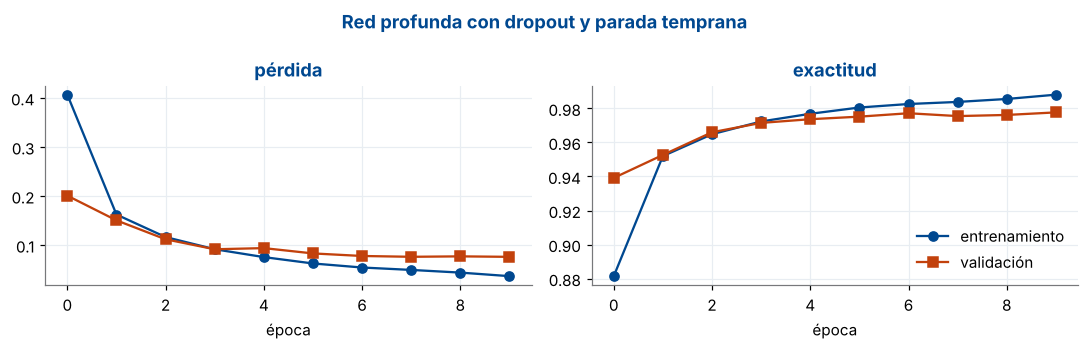

In [6]:
torch.manual_seed(SEED)
profunda = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(128, 10),
)
t0 = time.perf_counter()
h3 = entrenar(profunda, epocas=20, paciencia=2)
resultados["2 capas ocultas + dropout"] = (exactitud_y_perdida(profunda, x_te, y_te)[0], n_parametros(profunda), time.perf_counter() - t0)
print(f"Se detuvo en la época {len(h3['loss'])} · exactitud en la prueba: {resultados['2 capas ocultas + dropout'][0]:.4f}")
curvas(h3, "Red profunda con dropout y parada temprana")

## Parte 4 · Red convolucional

Las capas densas tratan cada píxel por separado y olvidan que la imagen es una cuadrícula. Una **convolución** desliza filtros pequeños (3 × 3) por toda la imagen: detecta bordes y trazos en cualquier posición con muy pocos parámetros. `MaxPool2d` reduce el tamaño quedándose con la respuesta más fuerte de cada zona.

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Dropout(p=0.3, inplace=False)
  (8): Linear(in_features=800, out_features=10, bias=True)
)


Exactitud en la prueba: 0.9820 · parámetros: 12810


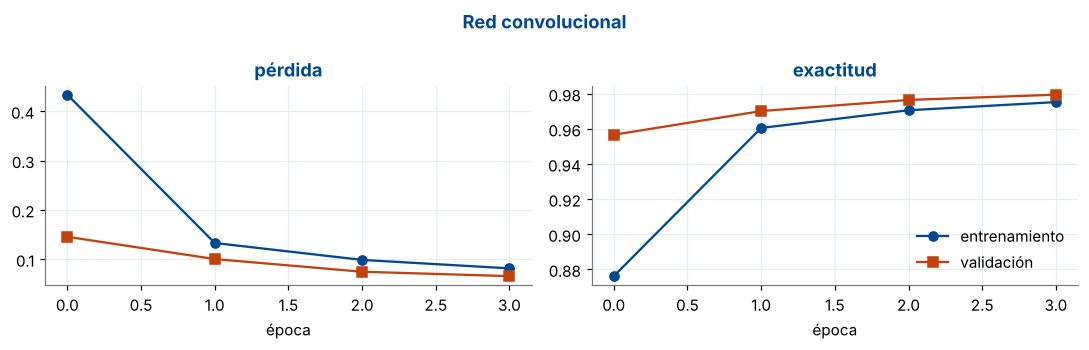

In [7]:
def crear_cnn():
    """Dos bloques convolución + ReLU + max-pooling y una capa lineal de salida."""
    return nn.Sequential(
        nn.Conv2d(1, 16, 3), nn.ReLU(), nn.MaxPool2d(2),     # 28×28 → 26×26 → 13×13
        nn.Conv2d(16, 32, 3), nn.ReLU(), nn.MaxPool2d(2),    # 13×13 → 11×11 → 5×5
        nn.Flatten(), nn.Dropout(0.3),
        nn.Linear(32 * 5 * 5, 10),
    )


torch.manual_seed(SEED)
cnn = crear_cnn()
print(cnn)
t0 = time.perf_counter()
h4 = entrenar(cnn, epocas=4)
resultados["Convolucional (2 capas conv.)"] = (exactitud_y_perdida(cnn, x_te, y_te)[0], n_parametros(cnn), time.perf_counter() - t0)
print(f"Exactitud en la prueba: {resultados['Convolucional (2 capas conv.)'][0]:.4f} · parámetros: {n_parametros(cnn)}")
curvas(h4, "Red convolucional")

**Qué aprendieron los filtros.** Los 16 filtros de la primera capa, de 3 × 3: muchos parecen detectores de bordes en distintas direcciones.

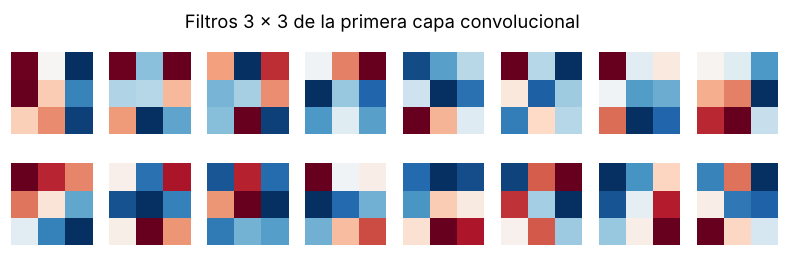

In [8]:
filtros = cnn[0].weight.detach().cpu()[:, 0]          # (16, 3, 3)
fig, axs = plt.subplots(2, 8, figsize=(9, 2.4))
for k, ax in enumerate(axs.ravel()):
    ax.imshow(filtros[k], cmap="RdBu"); ax.axis("off")
plt.suptitle("Filtros 3 × 3 de la primera capa convolucional", y=1.02); plt.show()

### La tabla: redes frente a modelos clásicos

Como referencia, en L1.2 la mejor SVM con kernel RBF obtuvo ≈ 0.97 entrenando con 10 000 imágenes.

In [9]:
print(f"{'modelo':<32}{'exactitud':>10}{'parámetros':>12}{'tiempo (s)':>12}")
for nombre, (acc, npar, t) in resultados.items():
    print(f"{nombre:<32}{acc:>10.4f}{npar:>12,}{t:>12.1f}")
assert resultados["Convolucional (2 capas conv.)"][0] > 0.98

modelo                           exactitud  parámetros  tiempo (s)
1 capa (softmax)                    0.9213       7,850         3.1
1 capa oculta (128)                 0.9683     101,770         3.4
2 capas ocultas + dropout           0.9800     235,146        12.0
Convolucional (2 capas conv.)       0.9820      12,810        13.7


**Tu turno.** ¿Qué red tiene más parámetros: la de dos capas ocultas o la convolucional? ¿Cuál acierta más? ¿Qué te dice eso sobre la importancia de la **arquitectura**?

> **Respuesta de referencia**

La red de dos capas ocultas tiene 18 veces más parámetros (235 146) que la convolucional (12 810) y, aun así, la convolucional acierta algo más, con menos épocas (4 frente a 10). La arquitectura incorpora un conocimiento previo útil (los patrones de una imagen son locales y pueden aparecer en cualquier posición), y eso vale más que agregar parámetros.

## Parte 5 · Escala realista: Fashion-MNIST

La misma red convolucional, ahora con fotos de prendas. Es más difícil: una camisa y una camiseta se parecen mucho.

In [10]:
import gzip


def cargar_fashion():
    """Fashion-MNIST (formato IDX comprimido) como tensores de PyTorch."""
    def imagenes(nombre):
        with gzip.open(descargar(nombre)) as f:
            return torch.tensor(np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 1, 28, 28), dtype=torch.float32) / 255.0

    def etiquetas(nombre):
        with gzip.open(descargar(nombre)) as f:
            return torch.tensor(np.frombuffer(f.read(), np.uint8, offset=8), dtype=torch.long)
    return (imagenes("train-images-idx3-ubyte.gz"), etiquetas("train-labels-idx1-ubyte.gz"),
            imagenes("t10k-images-idx3-ubyte.gz"), etiquetas("t10k-labels-idx1-ubyte.gz"))


f_tr, fy_tr, f_te, fy_te = cargar_fashion()
datos_f = random_split(TensorDataset(f_tr, fy_tr), [len(f_tr) - validacion, validacion], generator=torch.Generator().manual_seed(SEED))
torch.manual_seed(SEED)
cnn_f = crear_cnn()
entrenar(cnn_f, epocas=4, datos=datos_f)
acc_f = exactitud_y_perdida(cnn_f, f_te, fy_te)[0]
print(f"Fashion-MNIST · red convolucional: exactitud en la prueba = {acc_f:.4f} (en L1.2, la SVM obtuvo ≈ 0.87 con 10 000 imágenes)")

Fashion-MNIST · red convolucional: exactitud en la prueba = 0.8651 (en L1.2, la SVM obtuvo ≈ 0.87 con 10 000 imágenes)


Con solo 4 épocas y 16 y 32 filtros, esta red pequeña queda a la par de la SVM de L1.2. **Reto:** súbele épocas (con parada temprana) o filtros y mira cuánto mejora; anota el tiempo que te cuesta cada mejora.

## Para llevar a la sesión 2

1. Una red neuronal es una composición de regresiones logísticas con activaciones no lineales, entrenada con descenso de gradiente y retropropagación: en PyTorch ves los cuatro pasos en cada mini-lote.
2. Más capas y neuronas dan más capacidad y más riesgo de sobreajuste; se controla con validación, *dropout* y parada temprana, como cualquier modelo.
3. En imágenes, la arquitectura (convoluciones) importa más que el número de parámetros. En datos tabulares, los árboles potenciados y los modelos de la sesión 1 siguen siendo muy competitivos.
4. En la sesión 2 veremos cómo se entrena esto a escala: PyTorch con GPU e infraestructuras de altas prestaciones.

## Desafío opcional con IA agéntica · Mejorar la red convolucional sin hacer trampa

**Objetivo.** Usar un asistente de IA para mejorar la red de Fashion-MNIST y comprobar que la mejora es real y no viene de mirar la prueba.

**Prompt inicial.** Úsalo en la herramienta que prefieras (Claude Code, Codex, Gemini en Colab, ChatGPT…), con este notebook resuelto como contexto. Pide primero un plan y revisa cada paso antes de aprobarlo.

```text
En el notebook resuelto LT.1 (PyTorch con MNIST y Fashion-MNIST), muéstrame primero un plan y espera mi aprobación. Luego propón dos cambios a la red convolucional de Fashion-MNIST (por ejemplo, más filtros, normalización por lotes con nn.BatchNorm2d o aumento de datos) y compáralos con la red original usando la misma partición de validación (el random_split del notebook, con la misma semilla) y parada temprana. Reporta la exactitud de validación, el número de parámetros y el tiempo de entrenamiento de cada variante, y evalúa en la prueba solo la variante elegida.
```

**Cómo verificar el resultado**

- La variante se elige con la validación; la prueba se usa una sola vez, al final.
- La tabla incluye parámetros y tiempo, no solo exactitud.
- Puedes explicar con tus palabras qué hace cada cambio que propuso la IA.

**Declara el uso de IA** (como pide el sílabo): herramienta, prompts relevantes, qué verificaste tú y qué corregiste. El desafío es opcional y no se califica; lo que cuenta es que puedas explicar cada decisión.